# Fine-tuning YOLO11 for self-checkout

**Goal:** see how well a pretrained YOLO11 detects our products out of the box, then how much fine-tuning a **small (s)** model with a frozen backbone helps. Section 5 explains why s and not m or l.

**Production setting:** a fixed camera streams ~30 fps to cloud inference, and each frame holds **one item**. What matters per frame: *is the most confident box the right product, in the right place?*

Sections:
1. Dataset
2. Out-of-the-box baselines
3. Fine-tuning (with augmentation)
4. Results
5. Why yolo11s on the 30 s videos
6. Takeaways

Run from anywhere with `uv sync --group ml`, then select the project's `.venv` as the kernel.

In [1]:
import os
import sys
from pathlib import Path

# Work from the repo root so the paths match the README and the scripts
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "ml" / "scripts"))

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage, ImageDraw
from ultralytics import YOLO
from ultralytics.utils import LOGGER, YAML

import evaluate  # ml/scripts/evaluate.py: shared scoring code

LOGGER.setLevel("WARNING")  # hide per-image Ultralytics logs
plt.rcParams["figure.dpi"] = 60  # keeps the saved notebook small
DATA = ROOT / "ml" / "datasets" / "food"
NAMES = YAML.load(DATA / "data.yaml")["names"]
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 4060


## 1. Dataset

4 products, shot top-down on a bedsheet, one item per frame, built by `ml/scripts/prepare_dataset.py`. **Train** is ~93 frames per product sampled at 3 fps from a ~30 s phone video of the item being turned in hand, with plenty of end-on views (cap, lid, can top). **Val/test** are the 15 separate HEIC photos per product, split 7/8, so the model is scored on a different capture session than it trained on. Every image is 1280x720 landscape (portrait ones rotated, 4:3 photos centre-cropped without looking at the box, so a tall item can be cut off), so orientation and shape can't hint at the class. The class comes from the capture folder. Boxes cover the item only, never the hand: YOLOE-11l with generic shape prompts (can, bottle, jar, tub, container, cup) draws them, every box was checked by eye, and 19 were fixed by hand (mostly white caps and lids that blend into the sheet). Where the hand hides an end, the box covers the item's estimated full extent.

In [2]:
rows = []
for split in ("train", "val", "test"):
    for f in (DATA / "labels" / split).glob("*.txt"):
        rows.append({"split": split, "class": NAMES[int(f.read_text().split()[0])]})
df = pd.DataFrame(rows)
counts = pd.crosstab(df["class"], df["split"])[["train", "val", "test"]]
counts.loc["total"] = counts.sum()
counts

split,train,val,test
class,,,
coca_cola,93,7,8
ice_cream,94,7,8
ketchup,93,7,8
nutella,93,7,8
total,373,28,32


Every labeled box in the val split (the train split looks the same):

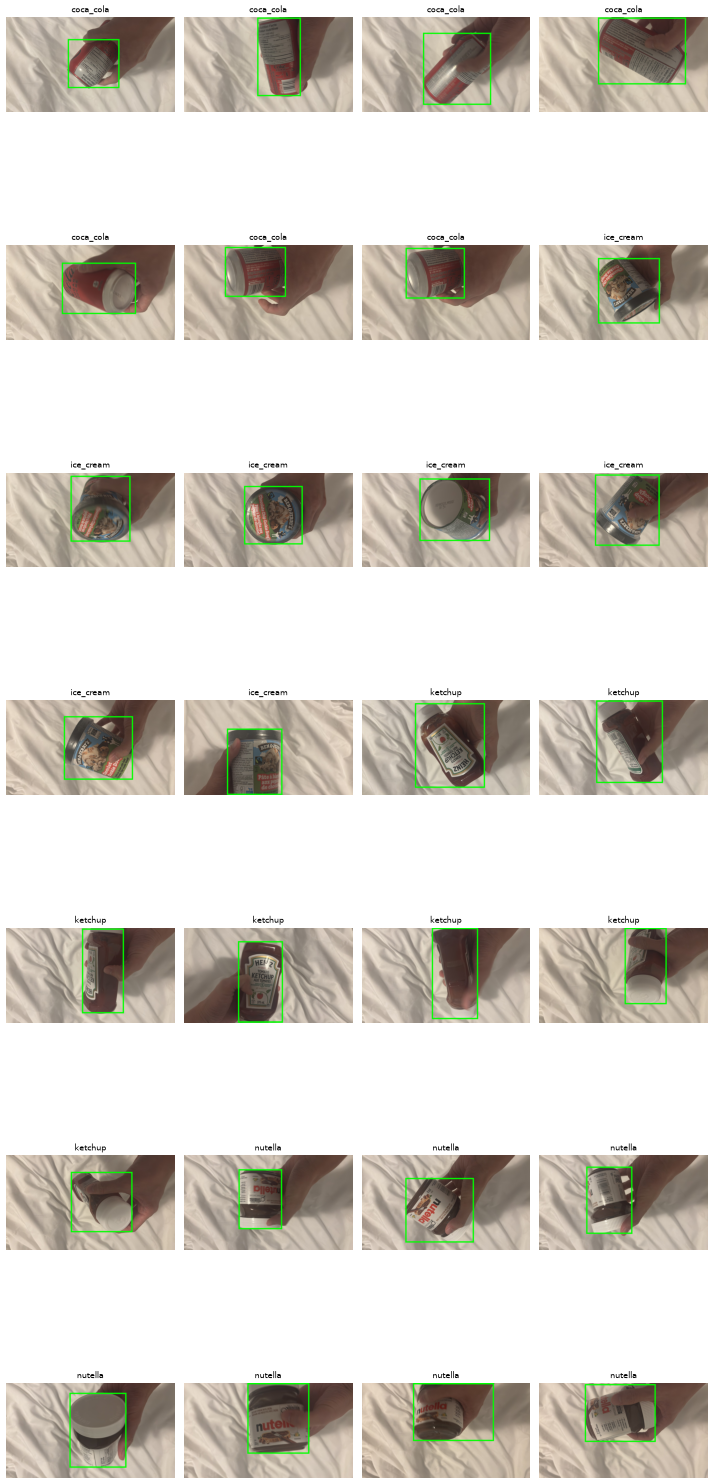

In [3]:
def show_labels(split, cols=5):
    imgs = sorted((DATA / "images" / split).glob("*.jpg"))
    fig, axes = plt.subplots((len(imgs) + cols - 1) // cols, cols, figsize=(3 * cols, 4 * ((len(imgs) + cols - 1) // cols)))
    for ax in axes.flat:
        ax.axis("off")
    for ax, img in zip(axes.flat, imgs):
        im = PILImage.open(img)
        W, H = im.size
        c, x, y, w, h = map(float, (DATA / "labels" / split / f"{img.stem}.txt").read_text().split())
        ImageDraw.Draw(im).rectangle([(x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H], outline="lime", width=10)
        ax.imshow(im)
        ax.set_title(NAMES[int(c)], fontsize=10)
    plt.tight_layout()
    plt.show()

show_labels("val", cols=4)

**Limitations to keep in mind:**
- Every photo has a hand holding the item and the same white bedsheet behind it. The kiosk will have a different surface and lighting, so expect a drop there.
- Val holds 7 and test 8 images per class (28 / 32). One test image moves a score by ~3%.
- Train frames come from one video per product, so consecutive frames are similar; 373 frames is less variety than 373 separate photos.

## 2. Out-of-the-box baselines

| Baseline | What it knows |
| --- | --- |
| **YOLO11 COCO** | 80 COCO classes. None of our products is one of them (the closest is the generic `bottle` / `cup`), so it scores 0 by definition. It is shown to make that point. |
| **YOLOE-11 zero-shot** | Open-vocabulary. We give it a text prompt per product (see `PROMPTS` below) and no training. |

**Top-1** = the most confident box has the correct class and overlaps the labeled box by IoU ≥ 0.5. **ms/frame** = preprocess + inference + postprocess on the local GPU (an RTX 4060, not the cloud GPU). At 30 fps the budget is 33 ms per frame.

In [4]:
evaluate.PROMPTS

['red Coca-Cola can',
 'Heinz ketchup bottle',
 "Ben & Jerry's ice cream tub",
 'Nutella jar']

## 3. Fine-tuning

yolo11s starts from COCO-pretrained weights with the **backbone frozen** (`freeze: 10`): the first 10 layers keep their COCO features, and only the neck and head learn our 4 products. It trains on our 373 video frames with the settings in `ml/configs/train.yaml`.

**Augmentation**, applied randomly each epoch so the model never sees exactly the same photo twice:

| Setting | Value | Why |
| --- | --- | --- |
| `hsv_h/s/v` | 0.015 / 0.7 / 0.4 | Store lighting and white balance vary |
| `degrees` | 180 | A top-down camera sees items at any angle |
| `translate`, `scale` | 0.1, 0.5 | Item position and distance from the camera |
| `shear`, `perspective` | 2.0, 0.0005 | Slight camera tilt |
| `fliplr`, `flipud` | **0** | A camera never sees a product mirrored; rotation already covers "no fixed up" |
| `mosaic`, `mixup`, `cutmix`, `copy_paste` | **0** | Production frames hold one item, so images are never combined |

**Optimizer:** AdamW at lr 0.0002, one step per batch, and no bias-LR warmup. Ultralytics' automatic choice (AdamW at lr 0.00125, one step per 64 images) made the class loss explode around epoch 8 on this small set.

Training runs up to 150 epochs and stops early if val mAP doesn't improve for 20 epochs. The checkpoint with the best val score is kept (`weights/best.pt`).

In [5]:
YAML.load(ROOT / "ml/configs/train.yaml")

{'task': 'detect',
 'mode': 'train',
 'data': 'ml/datasets/food/data.yaml',
 'exist_ok': True,
 'epochs': 150,
 'patience': 20,
 'freeze': 10,
 'imgsz': 640,
 'batch': 8,
 'device': 0,
 'workers': 2,
 'seed': 0,
 'deterministic': True,
 'optimizer': 'AdamW',
 'lr0': 0.0002,
 'nbs': 8,
 'warmup_bias_lr': 0.0,
 'hsv_h': 0.015,
 'hsv_s': 0.7,
 'hsv_v': 0.4,
 'degrees': 180,
 'translate': 0.1,
 'scale': 0.5,
 'shear': 2.0,
 'perspective': 0.0005,
 'fliplr': 0.0,
 'flipud': 0.0,
 'mosaic': 0.0,
 'mixup': 0.0,
 'cutmix': 0.0,
 'copy_paste': 0.0,
 'close_mosaic': 0}

In [6]:
# One line per epoch. "<- saved best.pt" marks a new best checkpoint on val.
# Ultralytics' own per-batch log is hidden by LOGGER.setLevel("WARNING") above.
def log_epoch(trainer):
    m = trainer.metrics
    best = "  <- saved best.pt" if trainer.fitness == trainer.best_fitness else ""
    print(
        f"{trainer.args.name} epoch {trainer.epoch + 1:3d}/{trainer.epochs}"
        f"  train loss {sum(map(float, trainer.tloss.values())):.3f}"
        f"  val mAP50 {m['metrics/mAP50(B)']:.3f}  mAP50-95 {m['metrics/mAP50-95(B)']:.3f}{best}",
        flush=True,
    )

name = "yolo11s"
model = YOLO(f"{name}.pt")
model.add_callback("on_fit_epoch_end", log_epoch)
model.train(cfg="ml/configs/train.yaml", name=name)
print(f"{name} done: weights in runs/detect/{name}/weights/")

yolo11s epoch   1/150  train loss 10.939  val mAP50 0.695  mAP50-95 0.377  <- saved best.pt


yolo11s epoch   2/150  train loss 5.237  val mAP50 0.905  mAP50-95 0.523  <- saved best.pt


yolo11s epoch   3/150  train loss 4.025  val mAP50 0.788  mAP50-95 0.529  <- saved best.pt


yolo11s epoch   4/150  train loss 3.688  val mAP50 0.889  mAP50-95 0.613  <- saved best.pt


yolo11s epoch   5/150  train loss 3.474  val mAP50 0.950  mAP50-95 0.629  <- saved best.pt


yolo11s epoch   6/150  train loss 3.146  val mAP50 0.970  mAP50-95 0.686  <- saved best.pt


... (54 outputs left out)

yolo11s epoch  61/150  train loss 1.983  val mAP50 0.986  mAP50-95 0.777


yolo11s epoch  62/150  train loss 1.988  val mAP50 0.978  mAP50-95 0.810


yolo11s epoch  63/150  train loss 1.988  val mAP50 0.976  mAP50-95 0.834


yolo11s done: weights in runs/detect/yolo11s/weights/


Training curves. The losses should fall, and val mAP should rise and then level off.

yolo11s: 62 epochs, best val mAP50-95 0.834 at epoch 42


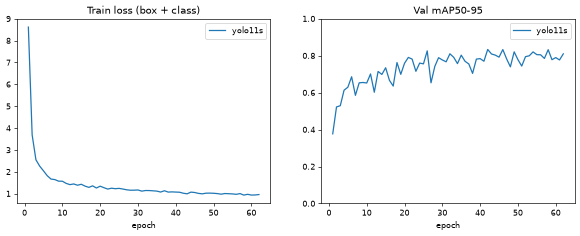

In [7]:
for name in ("yolo11s",):
    df = pd.read_csv(f"runs/detect/{name}/results.csv")
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    print(f"{name}: {len(df)} epochs, best val mAP50-95 {best['metrics/mAP50-95(B)']:.3f} at epoch {int(best['epoch'])}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ("yolo11s",):
    df = pd.read_csv(f"runs/detect/{name}/results.csv")
    axes[0].plot(df["epoch"], df["train/box_loss"] + df["train/cls_loss"], label=name)
    axes[1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label=name)
axes[0].set(title="Train loss (box + class)", xlabel="epoch")
axes[1].set(title="Val mAP50-95", xlabel="epoch", ylim=(0, 1))
for ax in axes:
    ax.legend()
plt.show()

## 4. Results

The same scoring is applied to every model. mAP is only computed for the fine-tuned models, because the baselines don't share our class list. **Val+test errors** splits the misses into wrong class, loose box (right class but IoU < 0.5) and no box.

In [8]:
WEIGHTS = ["runs/detect/yolo11s/weights/best.pt"]
display(Markdown(evaluate.compare(WEIGHTS)))

| Model | Val top-1 | Test top-1 | Val+test errors | Test mAP50 | Test mAP50-95 | ms/frame |
| --- | --- | --- | --- | --- | --- | --- |
| yolo11m COCO (no matching classes) | 0% | 0% | wrong class 60, loose box 0, no box 0 | - | - | 13.1 |
| yoloe-11m zero-shot | 39% | 31% | wrong class 26, loose box 0, no box 13 | - | - | 18.4 |
| yolo11l COCO (no matching classes) | 0% | 0% | wrong class 60, loose box 0, no box 0 | - | - | 19.1 |
| yoloe-11l zero-shot | 43% | 47% | wrong class 23, loose box 0, no box 10 | - | - | 25.1 |
| yolo11s fine-tuned | 93% | 100% | wrong class 2, loose box 0, no box 0 | 0.995 | 0.842 | 10.8 |

Predictions on the held-out test photos. The title shows the true class, then the predicted class with its confidence and the outcome. Green only when the class is right *and* the box overlaps the label by IoU ≥ 0.5.

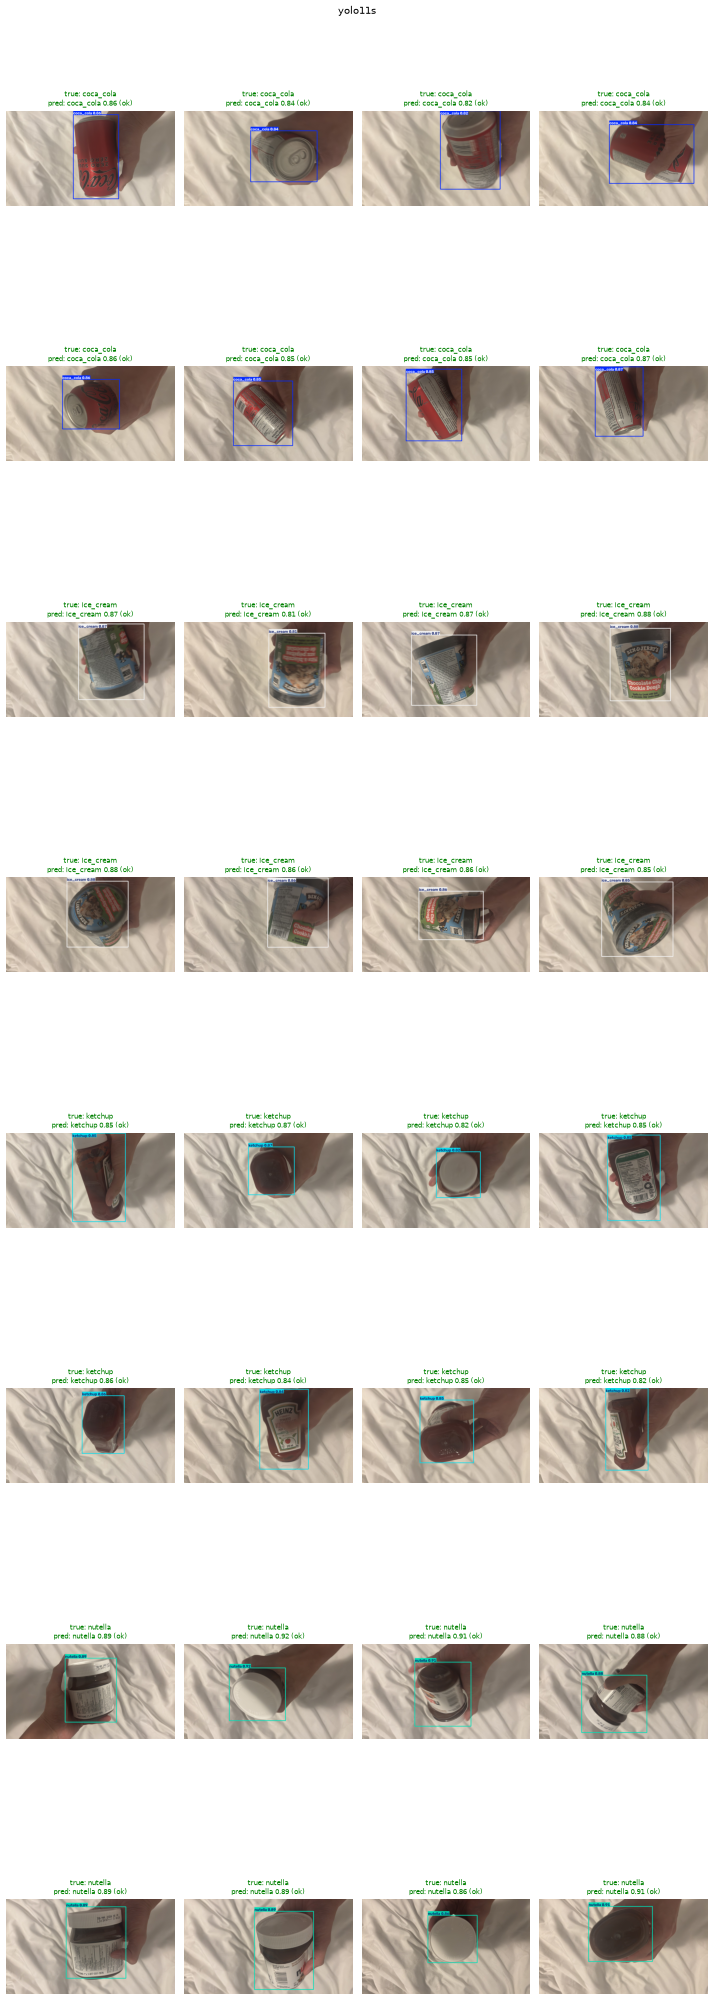

In [9]:
def show_predictions(weights, split="test"):
    model = YOLO(weights)
    imgs = sorted((DATA / "images" / split).glob("*.jpg"))
    fig, axes = plt.subplots((len(imgs) + 3) // 4, 4, figsize=(12, 4.5 * ((len(imgs) + 3) // 4)))
    for ax in axes.flat:
        ax.axis("off")
    for ax, img in zip(axes.flat, imgs):
        outcome, r = evaluate.judge(model, split, img)
        true = NAMES[int((DATA / "labels" / split / f"{img.stem}.txt").read_text().split()[0])]
        if len(r.boxes):
            i = int(r.boxes.conf.argmax())
            pred = f"{r.names[int(r.boxes.cls[i])]} {float(r.boxes.conf[i]):.2f}"
        else:
            pred = "nothing"
        ax.imshow(r.plot()[..., ::-1])
        ax.set_title(f"true: {true}\npred: {pred} ({outcome})", fontsize=8, color="green" if outcome == "ok" else "red")
        ax.axis("off")
    fig.suptitle(Path(weights).parents[1].name)
    plt.tight_layout()
    plt.show()

for w in WEIGHTS:
    show_predictions(w)

### Swipe clips

The short checkout-swipe clips (5 per product: 2 from the first session, 3 newer ones at varying speed, height and rotation; never trained on) are the closest thing to real use: the item moves through the frame, so many frames are blurred or show it only partly. Every frame is scored, prepared like the dataset.

- **Per frame:** the class of the most confident box (conf ≥ 0.25). *No box* is expected while the item enters or leaves.
- **Vote:** each frame's top box adds its confidence to its class, and the clip goes to the highest total. This is what the backend can do over a swipe.

In [10]:
for w in WEIGHTS:
    display(Markdown(f"**{Path(w).parents[1].name}**\n\n" + evaluate.swipes(YOLO(w))))

**yolo11s**

| Clip | Item | Frames | No box | Right | Wrong | Vote |
| --- | --- | --- | --- | --- | --- | --- |
| coca cola/IMG_1008.MOV | coca_cola | 71 | 39 | 32 | 0 | coca_cola |
| coca cola/IMG_1013.MOV | coca_cola | 46 | 29 | 17 | 0 | coca_cola |
| coca cola/IMG_1056.MOV | coca_cola | 42 | 40 | 0 | 2 (ketchup 2) | ketchup (wrong) |
| coca cola/IMG_1057.MOV | coca_cola | 37 | 34 | 2 | 1 (ketchup 1) | coca_cola |
| coca cola/IMG_1058.MOV | coca_cola | 42 | 24 | 7 | 11 (ketchup 11) | ketchup (wrong) |
| ketchup/IMG_1018.MOV | ketchup | 84 | 54 | 30 | 0 | ketchup |
| ketchup/IMG_1020.MOV | ketchup | 49 | 32 | 17 | 0 | ketchup |
| ketchup/IMG_1059.MOV | ketchup | 46 | 43 | 2 | 1 (nutella 1) | ketchup |
| ketchup/IMG_1060.MOV | ketchup | 38 | 26 | 10 | 2 (nutella 2) | ketchup |
| ketchup/IMG_1061.MOV | ketchup | 50 | 38 | 12 | 0 | ketchup |
| ice cream/IMG_1015.MOV | ice_cream | 66 | 28 | 36 | 2 (nutella 2) | ice_cream |
| ice cream/IMG_1016.MOV | ice_cream | 71 | 57 | 11 | 3 (nutella 2, coca_cola 1) | ice_cream |
| ice cream/IMG_1053.MOV | ice_cream | 79 | 58 | 20 | 1 (nutella 1) | ice_cream |
| ice cream/IMG_1054.MOV | ice_cream | 42 | 32 | 8 | 2 (nutella 2) | ice_cream |
| ice cream/IMG_1055.MOV | ice_cream | 43 | 29 | 13 | 1 (coca_cola 1) | ice_cream |
| nutella/IMG_1022.MOV | nutella | 60 | 28 | 32 | 0 | nutella |
| nutella/IMG_1025.MOV | nutella | 44 | 33 | 11 | 0 | nutella |
| nutella/IMG_1062.MOV | nutella | 51 | 35 | 16 | 0 | nutella |
| nutella/IMG_1063.MOV | nutella | 41 | 29 | 11 | 1 (ketchup 1) | nutella |
| nutella/IMG_1064.MOV | nutella | 39 | 29 | 10 | 0 | nutella |

Per frame: 297 of 324 frames with a box are right (92%); 717 of 1041 frames have no box.
Vote: 18 of 20 clips right.

## 5. Why yolo11s on the 30 s videos

Every setup below was trained 3 times with different seeds, because on a dataset this small a single run can be lucky or unlucky. Photos are the 60 val+test HEIC photos; swipes are the 20 swipe clips scored by vote (60 = 20 clips × 3 seeds).

**Model size** (all on the earlier ~15 s videos, backbone frozen, early stop at 20):

| Model | Val / test top-1 (mean) | Lowest seed on photos | Swipes right | Train time |
| --- | --- | --- | --- | --- |
| yolo11m | 89% / 88% | 72% | 46 / 60 | 6.9 min |
| **yolo11s** | **93% / 93%** | **86%** | **50 / 60** | **3.2 min** |
| yolo11n | 87% / 86% | 78% | 44 / 60 | 2.2 min |

The smaller model was both more accurate and steadier between seeds on this little data. Freezing the backbone let early stopping kick in sooner: stopping after 20 flat epochs instead of 50 cost at most 0.017 val mAP50-95.

**Training video** (yolo11s, same settings):

| Train frames | Photos (mean) | Lowest seed on photos | Swipes right | Train time |
| --- | --- | --- | --- | --- |
| ~15 s videos (199) | 93% / 93% | 86% | 50 / 60 | 3.2 min |
| half of the ~30 s videos (188) | 96% / 96% | 93% | 51 / 60 | 3.4 min |
| **~30 s videos (373)** | **95% / 99%** | **93%** | **53 / 60** | **6.3 min** |

The 30 s videos show the items end-on, which is how many swipes see them. Half of their frames already fixes the newer swipe clips (30 / 36 either way), but all of them are needed to keep the older clips and the seeds consistent.


## 6. Takeaways

- **Out of the box doesn't work for our products.** COCO YOLO11 has no matching classes (0%). The best zero-shot option, YOLOE-11l, reaches 43% val and 47% test top-1.
- **Fine-tuned yolo11s:** 93% val and 100% test top-1 (2 of 60 photos wrong), test mAP50 0.995. Training stopped at epoch 62 and kept epoch 42, in about 4 minutes on an RTX 4060.
- **Swipes: 18 of 20 clips right by vote**, and 92% of the frames that have a box are right. About two thirds of the frames have no box: the item is entering, leaving or blurred.
- **Both misses charge the wrong item.** Two Coca-Cola swipes (IMG_1056, IMG_1058) were voted ketchup. IMG_1056 had only 2 boxed frames out of 42, both ketchup; IMG_1058 had 11 ketchup frames against 7 Coca-Cola ones. That's 10% wrong charges on this run, above the 5% MVP target. A rescan rule (ask for a rescan when too few frames vote, or when the winner's lead is small) would turn IMG_1056 into a rescan instead of a wrong charge.
- **Seeds matter on this little data.** Across 3 seeds this setup got 53 of 60 swipes and 93% or better on photos every time (section 5); this notebook's run is seed 0.
- **Speed:** about 11 ms/frame on an RTX 4060, well inside the 33 ms budget for 30 fps.
- **Caveat:** everything was shot on the same bedsheet in the same lighting, and test has 32 photos (8 per class, about 3% each). Re-check on footage from the real kiosk.
